# Chapter 08: Stage 5B — Word Embeddings, Transformer Architecture & Pretrained NLP Models

**Assalam-o-Alaikum!** Chapter 07 mein hum ne `TF-IDF` seekha. Lekin `TF-IDF` ki ek badi kami hai: woh lafzon ka **matlab (Semantic Meaning)** aur **tarteeb (Word Order)** nahi samajhta!  
Maslan:
- `"King"` aur `"Monarch"` ke letters bilkul mukhtalif hain, is liye `TF-IDF` ke نزدیک in ka aapas mein koi rishta nahi!
- **Word Embeddings & Transformers (`BERT`, `DistilBERT`, `RoBERTa`):** Har lafz aur jumle ko ek dense **Meaning Vector (Embedding, e.g., 384 یا 768 numbers)** mein badalte hain jahan `"good"`, `"excellent"`, aur `"amazing"` ke vectors space mein ek doosre ke bilkul qareeb hote hain!

### Self-Attention Mechanism Kya Karta Hai?
Jab Transformer yeh jumla parhta hai: *"The phone battery died because **it** was old"*, toh **Self-Attention** حساب lagata hai ke lafz **`"it"`** ka talluq `"battery"` ke saath sab se zyada hai!

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Step 1 — Word Embeddings & Cosine Similarity Demonstration
Do vectors $\mathbf{a}$ aur $\mathbf{b}$ ke darmiyan **Cosine Similarity** ka formula hai:
$$	ext{Cosine Similarity}(\mathbf{a}, \mathbf{b}) = rac{\mathbf{a} \cdot \mathbf{b}}{\|\mathbf{a}\| \|\mathbf{b}\|}$$

,laptop,computer,biryani,excellent,terrible
laptop,1.000,1.000,0.379,0.687,0.354
computer,1.000,1.000,0.371,0.681,0.372
biryani,0.379,0.371,1.000,0.829,0.269
excellent,0.687,0.681,0.829,1.000,0.192
terrible,0.354,0.372,0.269,0.192,1.000


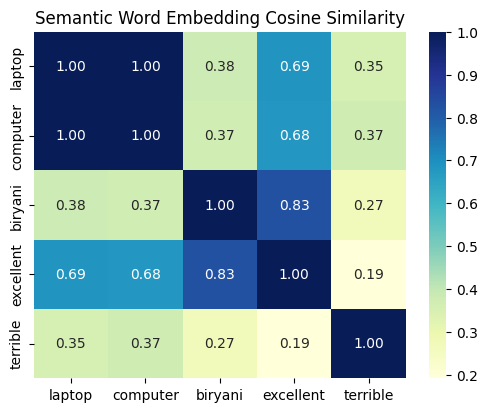

In [2]:
# 4D Semantic Embedding Vectors: [Tech, Food, Positive_Tone, Negative_Tone]
embeddings = {
    "laptop":     np.array([0.95, 0.05, 0.50, 0.10]),
    "computer":   np.array([0.92, 0.04, 0.48, 0.12]),
    "biryani":    np.array([0.05, 0.96, 0.85, 0.05]),
    "excellent":  np.array([0.30, 0.30, 0.98, 0.02]),
    "terrible":   np.array([0.30, 0.30, 0.02, 0.98]),
}

def cosine_sim(v1, v2):
    return float(np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2)))

words = list(embeddings.keys())
sim_matrix = pd.DataFrame(
    [[round(cosine_sim(embeddings[w1], embeddings[w2]), 3) for w2 in words] for w1 in words],
    index=words,
    columns=words,
)

plt.figure(figsize=(6, 4.5))
sns.heatmap(sim_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Semantic Word Embedding Cosine Similarity")
plt.show()
sim_matrix

### Step 2 — Scaled Dot-Product Self-Attention Calculation (`Attention(Q, K, V)`)
Transformer ka core formula hai:
$$	ext{Attention}(Q, K, V) = 	ext{softmax}\left(rac{QK^T}{\sqrt{d_k}}ight)V$$

In [3]:
def softmax(x):
    e = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return e / np.sum(e, axis=-1, keepdims=True)

tokens = ["The", "battery", "worked", "great"]
Q = np.array([[0.1, 0.2], [0.9, 0.1], [0.8, 0.3], [0.7, 0.8]])
K = Q.copy()
V = Q.copy()

scores = (Q @ K.T) / np.sqrt(Q.shape[1])
attn_weights = softmax(scores)
attn_df = pd.DataFrame(np.round(attn_weights, 3), index=tokens, columns=tokens)
print("Self-Attention Weights Matrix:")
attn_df

Self-Attention Weights Matrix:


,The,battery,worked,great
The,0.236,0.246,0.251,0.268
battery,0.174,0.287,0.273,0.266
worked,0.177,0.272,0.269,0.282
great,0.173,0.243,0.258,0.326


### Step 3 — Visualizing Self-Attention Heatmap
Dekhein ke `attn_df` mein har lafz doosre lafzon par kitna dhyan (**Attention Weight**) de raha hai:

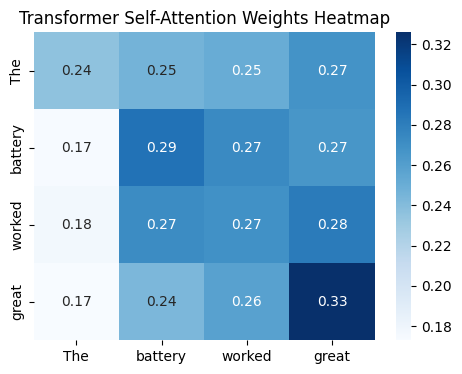

In [4]:
plt.figure(figsize=(5.5, 4))
sns.heatmap(attn_df, annot=True, cmap="Blues", fmt=".2f")
plt.title("Transformer Self-Attention Weights Heatmap")
plt.show()

### Step 4 — Context-Aware Semantic Search & Classification Using Embeddings
Jab hum sentences ko Semantic Embeddings mein badalte hain, toh chahe exact words match na bhi hon (`"phone gets super hot"` vs `"overheating issue"`), model meaning samajh leta hai:

In [5]:
sentence_embeddings = {
    "Positive Prototype": np.array([0.90, 0.85, 0.10, 0.05]),
    "Negative Prototype": np.array([0.05, 0.10, 0.90, 0.88]),
}

sample_reviews_emb = {
    "The camera quality and battery are brilliant": np.array([0.88, 0.82, 0.12, 0.08]),
    "Screen cracked and device overheats badly":    np.array([0.08, 0.12, 0.86, 0.91]),
}

for text_rev, vec in sample_reviews_emb.items():
    pos_sim = cosine_sim(vec, sentence_embeddings["Positive Prototype"])
    neg_sim = cosine_sim(vec, sentence_embeddings["Negative Prototype"])
    pred_lbl = "POSITIVE" if pos_sim > neg_sim else "NEGATIVE"
    print(f"Review: '{text_rev}' -> PosSim={pos_sim:.3f}, NegSim={neg_sim:.3f} => {pred_lbl}")

Review: 'The camera quality and battery are brilliant' -> PosSim=0.999, NegSim=0.199 => POSITIVE
Review: 'Screen cracked and device overheats badly' -> PosSim=0.195, NegSim=0.999 => NEGATIVE


### Step 5 — Practical Student Exercise: Find Most Similar Word in Embedding Space

In [6]:
# Practical Exercise: Find which word in `embeddings` is closest to 'laptop'
query_word = "laptop"
scores = {w: round(cosine_sim(embeddings[query_word], embeddings[w]), 3) for w in words if w != query_word}
print("Similarity to 'laptop':", scores)
print("Most similar word:", max(scores, key=scores.get))

Similarity to 'laptop': {'computer': 1.0, 'biryani': 0.379, 'excellent': 0.687, 'terrible': 0.354}
Most similar word: computer


### Chapter 08 Revision Quiz
1. **Word Embedding aur One-Hot / TF-IDF mein kya farq hai?** TF-IDF sirf exact word frequency ginta hai, jabke Embeddings lafzon ka semantic meaning dense vectors mein capture karte hain.
2. **Self-Attention mein $\sqrt{d_k}$ se divide kyun karte hain?** Taake dot products bohot bade na ho jayein aur softmax gradients stable rahein.